# What drives the price of a car?

![](images/kurt.jpeg)

**OVERVIEW**

In this application, you will explore a dataset from Kaggle. The original dataset contained information on 3 million used cars. The provided dataset contains information on 426K cars to ensure speed of processing.  Your goal is to understand what factors make a car more or less expensive.  As a result of your analysis, you should provide clear recommendations to your client -- a used car dealership -- as to what consumers value in a used car.

### CRISP-DM Framework

<center>
    <img src = images/crisp.png width = 50%/>
</center>


To frame the task, throughout our practical applications, we will refer back to a standard process in industry for data projects called CRISP-DM.  This process provides a framework for working through a data problem.  Your first step in this application will be to read through a brief overview of CRISP-DM [here](https://mo-pcco.s3.us-east-1.amazonaws.com/BH-PCMLAI/module_11/readings_starter.zip).  After reading the overview, answer the questions below.

### Business Understanding

From a business perspective, we are tasked with identifying key drivers for used car prices.  In the CRISP-DM overview, we are asked to convert this business framing to a data problem definition.  Using a few sentences, reframe the task as a data task with the appropriate technical vocabulary. 

In CRISP‑DM terms, the business question “What drives used car prices?” is translated into a supervised learning and explanatory modeling problem. 

Specifically, the data task is to model used car transaction prices as a continuous target variable and to quantify the relationship between price and a set of candidate explanatory features (e.g., vehicle attributes, usage, age, market conditions, state of sale) using statistical and/or machine‑learning regression techniques. 

The objective is to identify and validate significant predictors, estimate their effect sizes, and assess model performance against defined success metrics (such as RMSE or R2R^2R2), so that the resulting model yields interpretable insights into the key price drivers rather than only point predictions.


Through this project, I will need to guide the dealer through different reports to make good decisions on how to improve their inventory and/or potentially their sales.

### Data Understanding

After considering the business understanding, we want to get familiar with our data.  Write down some steps that you would take to get to know the dataset and identify any quality issues within.  Take time to get to know the dataset and explore what information it contains and how this could be used to inform your business understanding.

Steps to explore the data:

  - Import the data
  - To identify each column, possible values, min, max and others
  - To identify missing values
  - Remove or adjust data set around missed values
  - Transform categorical columns using Target encoder
  - To identify relations of each column by executing correlations
  - To explore the importance of each column with the price

In [1]:
#Uploading all necessary liblaries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from sklearn.metrics import accuracy_score
from sklearn import set_config
set_config(display="diagram")

# for creating the profile report of data 
from ydata_profiling import ProfileReport

#Liblaries for preprocessing
from sklearn import preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PolynomialFeatures, OrdinalEncoder

#Liblaries for models
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, Lasso, ElasticNet, RidgeCV
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor, BaggingRegressor
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import TargetEncoder

#Liblaries for cross validation and model evaluation
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings("ignore")

import gc

plt.style.use('default')
sns.set_palette('husl')
np.random.seed(42)


In [2]:
car_resale = pd.read_csv('data/vehicles.csv')

In [3]:
car_resale.head(10)

,id,region,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,VIN,drive,size,type,paint_color,state
0,7222695916,prescott,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,az
1,7218891961,fayetteville,11900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ar
2,7221797935,florida keys,21000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,fl
3,7222270760,worcester / central MA,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ma
4,7210384030,greensboro,4900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,nc
5,7222379453,hudson valley,1600,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ny
6,7221952215,hudson valley,1000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ny
7,7220195662,hudson valley,15995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ny
8,7209064557,medford-ashland,5000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,or
9,7219485069,erie,3000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,pa


In [4]:
car_resale.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 426880 entries, 0 to 426879
Data columns (total 18 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            426880 non-null  int64  
 1   region        426880 non-null  object 
 2   price         426880 non-null  int64  
 3   year          425675 non-null  float64
 4   manufacturer  409234 non-null  object 
 5   model         421603 non-null  object 
 6   condition     252776 non-null  object 
 7   cylinders     249202 non-null  object 
 8   fuel          423867 non-null  object 
 9   odometer      422480 non-null  float64
 10  title_status  418638 non-null  object 
 11  transmission  424324 non-null  object 
 12  VIN           265838 non-null  object 
 13  drive         296313 non-null  object 
 14  size          120519 non-null  object 
 15  type          334022 non-null  object 
 16  paint_color   296677 non-null  object 
 17  state         426880 non-null  object 
dtypes: f

In [5]:
car_resale.shape

(426880, 18)

In [6]:
car_resale.describe()

,id,price,year,odometer
count,4.268800e+05,4.268800e+05,425675.000000,4.224800e+05
mean,7.311487e+09,7.519903e+04,2011.235191,9.804333e+04
std,4.473170e+06,1.218228e+07,9.452120,2.138815e+05
min,7.207408e+09,0.000000e+00,1900.000000,0.000000e+00
25%,7.308143e+09,5.900000e+03,2008.000000,3.770400e+04
50%,7.312621e+09,1.395000e+04,2013.000000,8.554800e+04
75%,7.315254e+09,2.648575e+04,2017.000000,1.335425e+05
max,7.317101e+09,3.736929e+09,2022.000000,1.000000e+07


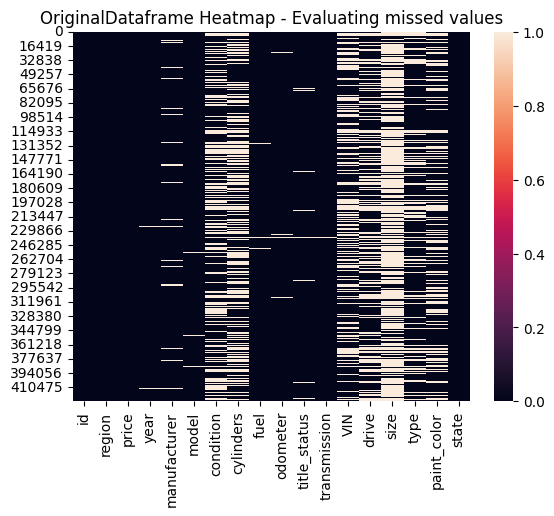

In [7]:
heatmap = sns.heatmap(
	car_resale.isna()
)
heatmap.set_title("OriginalDataframe Heatmap - Evaluating missed values")
plt.show()

In [8]:
#checking for column price where price = 0 
car_resale[car_resale['price'] == 0]    

,id,region,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,VIN,drive,size,type,paint_color,state
10,7218893038,el paso,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,tx
11,7218325704,el paso,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,tx
12,7217788283,el paso,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,tx
13,7217147606,el paso,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,tx
14,7209027818,el paso,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,tx
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
426764,7303347225,wyoming,0,2018.0,NaN,peterbilt 579,NaN,NaN,diesel,1.0,clean,automatic,NaN,NaN,NaN,NaN,NaN,wy
426812,7302877815,wyoming,0,2006.0,toyota,scion tc,excellent,4 cylinders,gas,195000.0,clean,automatic,JTKDE177460109655,fwd,NaN,NaN,silver,wy
426832,7302353283,wyoming,0,2004.0,toyota,prius,excellent,4 cylinders,hybrid,239000.0,clean,automatic,JTDKB20U840108051,fwd,NaN,NaN,blue,wy
426836,7302301268,wyoming,0,2018.0,ram,2500,excellent,6 cylinders,diesel,20492.0,clean,automatic,3C6UR5HL3JG307217,4wd,full-size,truck,white,wy


In [9]:
#   Removing rows where price is 0 as it is not possible to have a car with price 0 and it can be considered as an outlier in our dataset.
car_resale_cleaned = car_resale[car_resale['price'] != 0]


In [10]:
# Calculate missing value percentages for all columns
missing_percentage = car_resale_cleaned.isnull().mean() * 100
print(missing_percentage)

id               0.000000
region           0.000000
price            0.000000
year             0.297727
manufacturer     4.108024
model            1.193193
condition       38.425067
cylinders       40.714748
fuel             0.658401
odometer         0.581240
title_status     1.963019
transmission     0.462708
VIN             38.620252
drive           30.522482
size            71.813140
type            21.810983
paint_color     29.734381
state            0.000000
dtype: float64


In [11]:
# outputting the unique values for each column to an external file for further analysis
unique_values_dict = {col: pd.Series(car_resale_cleaned[col].unique()) for col in car_resale_cleaned.columns}
unique_df = pd.DataFrame(unique_values_dict)

#Export the new DataFrame to a CSV file
output_filename = 'data/unique_values_output.csv'
unique_df.to_csv(output_filename, index=False) # index=False prevents writing row indices to the CSV

### Data Preparation

After our initial exploration and fine-tuning of the business understanding, it is time to construct our final dataset prior to modeling.  Here, we want to make sure to handle any integrity issues and cleaning, the engineering of new features, any transformations that we believe should happen (scaling, logarithms, normalization, etc.), and general preparation for modeling with `sklearn`. 

In [12]:
null_columns = car_resale_cleaned.columns[car_resale_cleaned.isna().mean() > 0.01]
print(null_columns)
#data = car_resale.drop(null_columns, axis=1)

Index(['manufacturer', 'model', 'condition', 'cylinders', 'title_status',
       'VIN', 'drive', 'size', 'type', 'paint_color'],
      dtype='object')


Check if there is a possibility to find a make from a given Make - Model column combo and update the same for rows with missing make and viceversa for model 

In [13]:
# VIN - Drop , as it is a unique identifier for each car and it does not provide any useful information for our analysis and model building and it has a high percentage of missing values.
car_resale_cleaned.drop(columns=['VIN'], inplace=True)
#dropping the colums for Region as its covered in the state column
car_resale_cleaned.drop(columns=['region'], inplace=True)
#we drop colums for id, cyclinders , paint color and size as they have a high percentage of missing values and they do not provide any useful information for our analysis and model building.
car_resale_cleaned.drop(columns=['id'], inplace=True)
car_resale_cleaned.drop(columns=['cylinders'], inplace=True)
car_resale_cleaned.drop(columns=['paint_color'], inplace=True)
car_resale_cleaned.drop(columns=['size'], inplace=True)


# for pice - we can use the median to fill the missing values
car_resale_cleaned['price'].fillna(car_resale_cleaned['price'].median(), inplace=True)
# for year - we can use the most common value  to fill the missing values
car_resale_cleaned['year'].fillna(car_resale_cleaned['year'].mode()[0], inplace=True)
# for manufacturer - we can use the Other to fill the missing values 
car_resale_cleaned['manufacturer'].fillna('Other', inplace=True)
# for model - we can use the Other to fill the missing values
car_resale_cleaned['model'].fillna('Other', inplace=True)
# for odometer - we can use the mean  to fill the missing values
car_resale_cleaned['odometer'].fillna(car_resale_cleaned['odometer'].mean(), inplace=True)
# for title_status - we can use the mode to fill the missing values
car_resale_cleaned['title_status'].fillna(car_resale_cleaned['title_status'].mode()[0], inplace=True)
# for transmission - we can use the mode to fill the missing values
car_resale_cleaned['transmission'].fillna(car_resale_cleaned['transmission'].mode()[0], inplace=True)
# for drive - we can use the mode to fill the missing values
car_resale_cleaned['drive'].fillna(car_resale_cleaned['drive'].mode()[0], inplace=True)
# for type - we can use the mode to fill the missing values
car_resale_cleaned['type'].fillna(car_resale_cleaned['type'].mode()[0], inplace=True)
#for condition - we can use the mode to fill the missing values
car_resale_cleaned['condition'].fillna(car_resale_cleaned['condition'].mode()[0], inplace=True)
#for fuel - we can use other to fill the missing values
car_resale_cleaned['fuel'].fillna('Other', inplace=True)   




In [14]:
car_resale_cleaned.isnull().sum()

price           0
year            0
manufacturer    0
model           0
condition       0
fuel            0
odometer        0
title_status    0
transmission    0
drive           0
type            0
state           0
dtype: int64

In [15]:
#create a profile report for the cleaned dataset to understand the data better and to identify any potential issues with the data that we need to address before building our models.

profile = ProfileReport(car_resale_cleaned, title="Car Resale Data Profiling Report", explorative=True)
profile.to_file("data/car_resale_cleaned_profile_report.html") 


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 12/12 [00:01<00:00,  6.27it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [16]:
profile

In [17]:
{column: len(car_resale_cleaned[column].unique()) for column in car_resale_cleaned.columns if car_resale_cleaned.dtypes[column] == 'object'}

{'manufacturer': 43,
 'model': 28266,
 'condition': 6,
 'fuel': 6,
 'title_status': 6,
 'transmission': 3,
 'drive': 3,
 'type': 13,
 'state': 51}

             price      year  odometer
price     1.000000 -0.004882  0.010801
year     -0.004882  1.000000 -0.164170
odometer  0.010801 -0.164170  1.000000


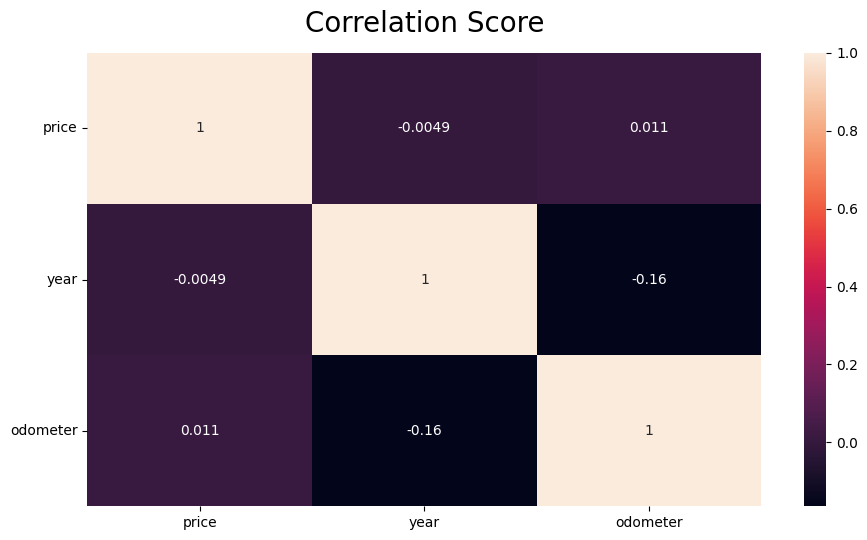

In [18]:
#plotting a correlation matrix to see the correlation between the numerical features in our dataset

correlation_matrix = car_resale_cleaned.corr(numeric_only=True)

print (correlation_matrix)

plt.figure(figsize=(9.5,5.5))
plt.title('Correlation Score', fontsize=20, pad=15)
sns.heatmap(correlation_matrix, annot=True)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


'\nsns.heatmap(corr, annot=True, cmap=\'coolwarm\', fmt=".2f")\nplt.title(\'Correlation Matrix\')\nplt.show()\n'

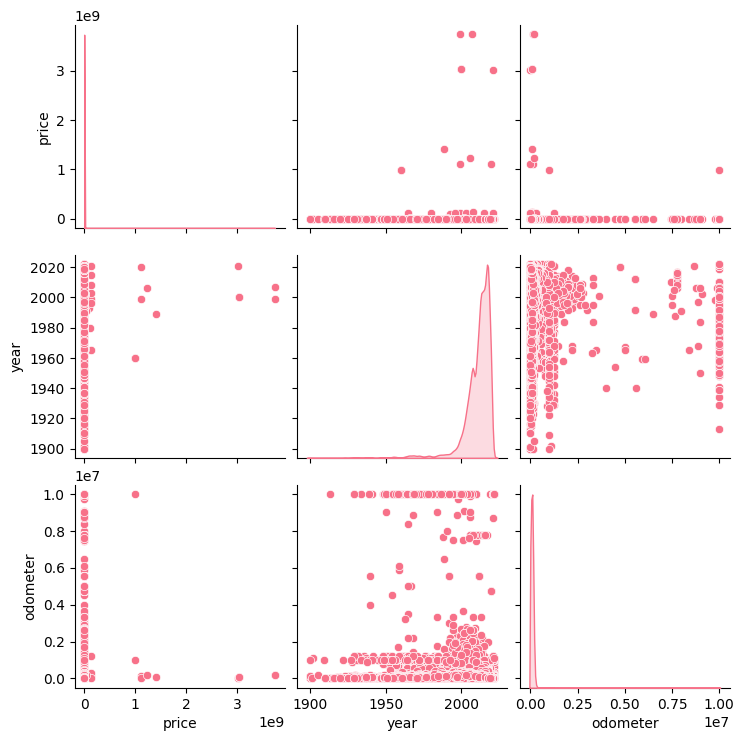

In [19]:
#pairplot to see the distribution of the numerical features in our dataset and the relationship between them

sns.pairplot(data = car_resale_cleaned, diag_kind = 'kde')

'''
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix')
plt.show()
'''

In [20]:
'''
# Function used to extract the first word of the model
def first_words(item):
    model = item["model"]
    segments = re.split(r"[, \!?:]+", model)
    index = 0
    value = segments[index]

    # If the model is compound with the manufacturer name
    if(value == item["manufacturer"]): 
        index += 1 
        if(len(segments) > index):
            value = segments[index]   

    return value.title() 

car_resale_cleaned['model'] = car_resale_cleaned['model'].str.replace('-', '')
car_resale_cleaned['model'] = car_resale_cleaned.apply(first_words, axis=1)

'''
# Removing inaccurate records: First vehicle with automstic transmission started at 1948
car_resale_cleaned = car_resale_cleaned.query('not(year < 1948 and transmission == "automatic")')

# Removing duplicated records
car_resale_cleaned = car_resale_cleaned.drop_duplicates()

car_resale_cleaned.sample(10)

,price,year,manufacturer,model,condition,fuel,odometer,title_status,transmission,drive,type,state
113792,15999,2015.0,bmw,428 gc,excellent,gas,94526.0,clean,automatic,4wd,coupe,fl
166186,33590,2019.0,nissan,titan crew cab sv pickup,good,gas,4245.0,clean,other,4wd,pickup,ks
85502,6500,2011.0,chevrolet,volt,good,gas,113000.0,clean,automatic,fwd,sedan,ct
60704,1600,2001.0,dodge,durango,fair,gas,225000.0,clean,automatic,4wd,SUV,ca
258450,7999,2009.0,mitsubishi,outlander,good,gas,91000.0,clean,automatic,4wd,sedan,nj
322304,5000,2010.0,chevrolet,silverado,good,gas,300000.0,clean,automatic,rwd,pickup,or
98108,47376,2019.0,ford,f150 xlt 4wd,good,gas,20238.0,clean,automatic,4wd,sedan,fl
157492,1900,2004.0,chevrolet,malibu,good,gas,150000.0,clean,automatic,fwd,sedan,ia
151533,26500,1998.0,Other,F800 DUMP TRUCK,excellent,diesel,139448.0,clean,automatic,rwd,truck,in
252452,3600,2001.0,chevrolet,silverado 1500 lt,good,gas,149050.0,clean,automatic,rwd,pickup,nj


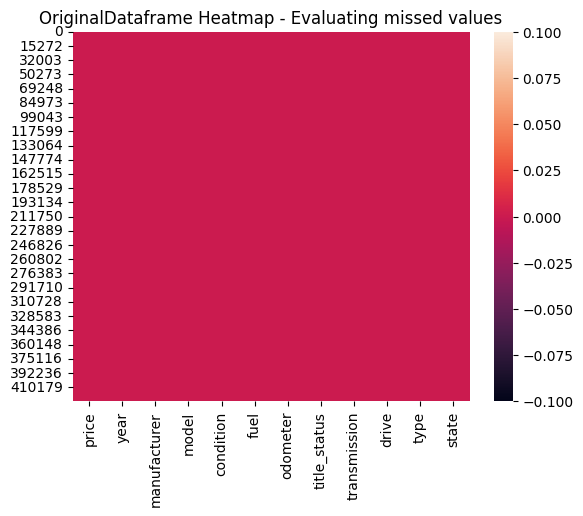

In [21]:
heatmap_cleaned = sns.heatmap(
	car_resale_cleaned.isna()
)
heatmap_cleaned.set_title("OriginalDataframe Heatmap - Evaluating missed values")
plt.show()

In [22]:

# finding the ourlier threshold using IQR method
Q1 = car_resale_cleaned['price'].quantile(0.25)
Q3 = car_resale_cleaned['price'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print(f"Lower Bound: {lower_bound}, Upper Bound: {upper_bound}")

Lower Bound: -21547.0, Upper Bound: 53245.0


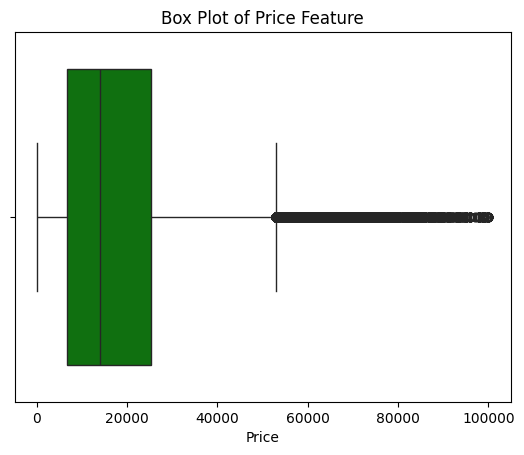

In [23]:
# given the negaitive values for price we will consider them as outliers and we will remove them from our dataset
car_resale_cleaned_sans_outliers = car_resale_cleaned[
    (car_resale_cleaned['price'] > 100) &
    (car_resale_cleaned['price'] < 100000)
]

#do a box plot to see the distribution of the price feature and to see the outliers in our dataset
sns.boxplot(x=car_resale_cleaned_sans_outliers['price'], color='green')
plt.title('Box Plot of Price Feature')
plt.xlabel('Price')
plt.show()

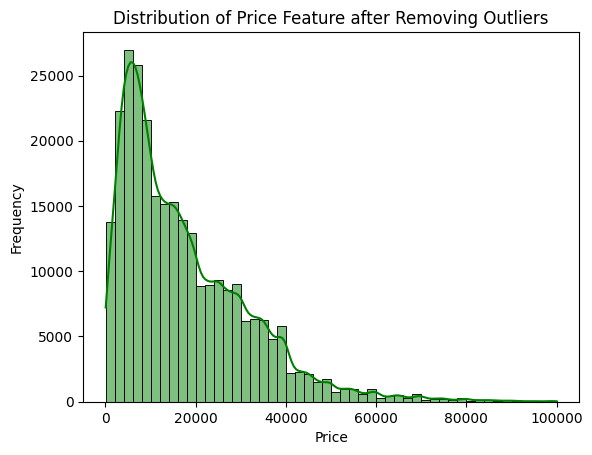

In [24]:
#review the price distribution after removing the outliers
sns.histplot(car_resale_cleaned_sans_outliers['price'], bins=50, kde=True, color='green')
plt.title('Distribution of Price Feature after Removing Outliers')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()


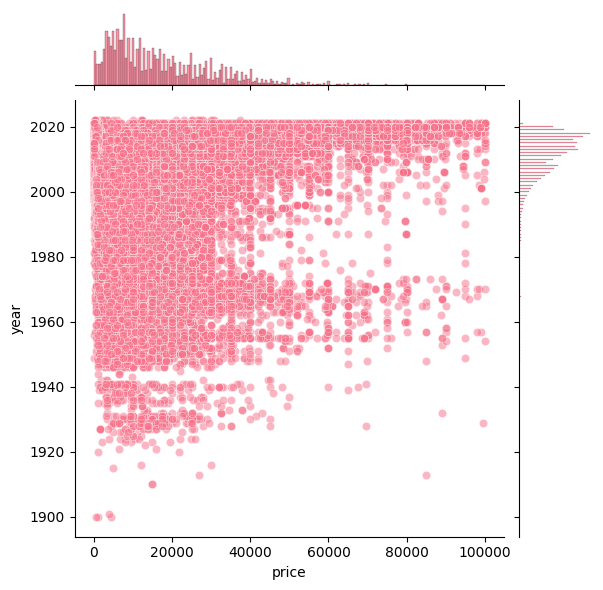

In [25]:
sns.jointplot(data=car_resale_cleaned_sans_outliers, x='price', y='year' , alpha=0.5)

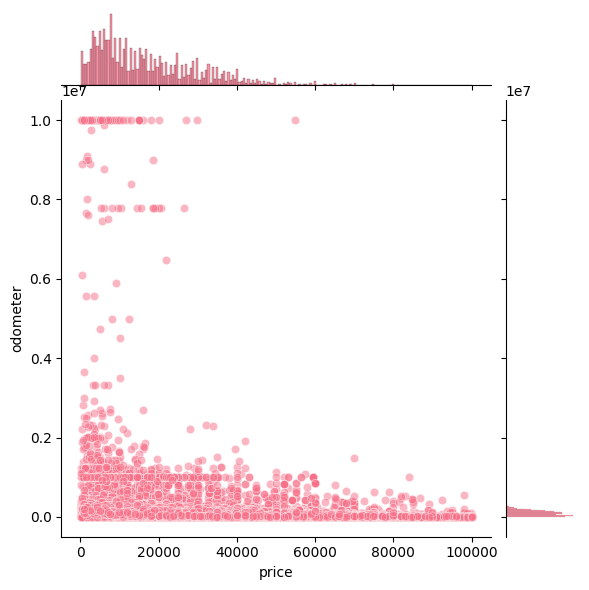

In [26]:
sns.jointplot(data=car_resale_cleaned_sans_outliers, x='price', y='odometer' , alpha=0.5)

In [27]:
# Numerical Summary
car_resale_cleaned.groupby('manufacturer')['price'].describe()

,count,mean,std,min,25%,50%,75%,max
manufacturer,,,,,,,,
Other,12259.0,41161.290807,1.577800e+06,1.0,5399.50,12990.0,28000.00,1.234568e+08
acura,3889.0,18921.533042,1.306044e+04,1.0,7995.00,16990.0,27990.00,1.399990e+05
alfa-romeo,524.0,28955.337786,6.546177e+03,99.0,27590.00,28990.0,31146.75,6.295000e+04
aston-martin,18.0,71001.555556,4.281551e+04,1947.0,42623.75,69470.0,78740.25,1.798880e+05
audi,5065.0,23798.448963,1.576005e+04,1.0,12200.00,22990.0,32898.00,1.600000e+05
bmw,9301.0,31530.403182,1.176306e+06,1.0,8950.00,16000.0,27900.00,1.134568e+08
buick,3621.0,47940.380558,2.051437e+06,1.0,4995.00,10995.0,20990.00,1.234568e+08
cadillac,4618.0,19509.285838,1.567065e+04,1.0,7000.00,15545.5,29667.75,1.950000e+05
chevrolet,35257.0,168400.264260,1.769468e+07,1.0,6826.00,14000.0,26900.00,3.009549e+09


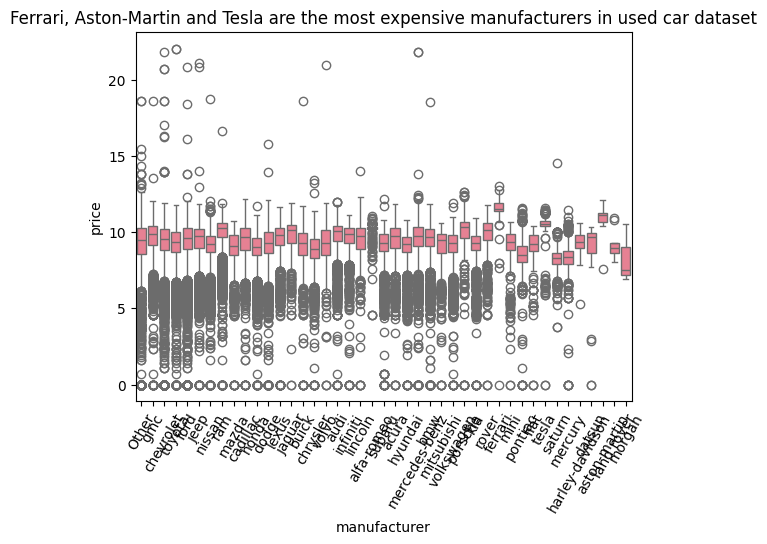

In [28]:
sns.boxplot(x = 'manufacturer', y = np.log(car_resale_cleaned['price']), data = car_resale_cleaned)
plt.xticks(rotation=60);
# a lot of variety for different manufactuer types
plt.title("Ferrari, Aston-Martin and Tesla are the most expensive manufacturers in used car dataset")
plt.savefig('1.png')

In [29]:
car_resale_cleaned.groupby('transmission')['price'].describe()

,count,mean,std,min,25%,50%,75%,max
transmission,,,,,,,,
automatic,223158.0,105184.976425,1.610390e+07,1.0,6000.0,11995.0,22218.0,3.736929e+09
manual,19734.0,248893.972687,1.663741e+07,1.0,4950.0,9500.0,18595.0,1.410065e+09
other,35069.0,31653.334170,6.620010e+05,1.0,20590.0,27990.0,34590.0,1.234568e+08


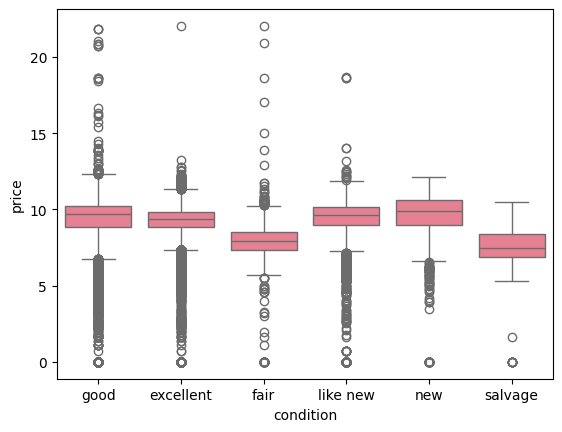

In [30]:
sns.boxplot(x = 'condition', y = np.log(car_resale_cleaned['price']), data = car_resale_cleaned);
# highest median price for new cars, lowest median for salvage 

In [31]:
'''encoded_df_price = encoded_df[['price_log']].sort_values(by = 'price_log', ascending = False).reset_index()
fig = px.bar(encoded_df_price[1:], x = 'index', y = 'price_log', color='index', labels={'price_log':'Price', 'index' : 'Feature'})
fig.update_layout(
    autosize=False,
    width=1000,
    height=600,
    title="Price Correlations"
)

fig.show()'''

'encoded_df_price = encoded_df[[\'price_log\']].sort_values(by = \'price_log\', ascending = False).reset_index()\nfig = px.bar(encoded_df_price[1:], x = \'index\', y = \'price_log\', color=\'index\', labels={\'price_log\':\'Price\', \'index\' : \'Feature\'})\nfig.update_layout(\n    autosize=False,\n    width=1000,\n    height=600,\n    title="Price Correlations"\n)\n\nfig.show()'

### Modeling

With your (almost?) final dataset in hand, it is now time to build some models.  Here, you should build a number of different regression models with the price as the target.  In building your models, you should explore different parameters and be sure to cross-validate your findings.

Creating the training and testing set from the cleaned data

In [32]:
# Create a list of the numerical and categorical features in our dataset to be used for feature engineering and model building.
    
num_features = [col for col in car_resale_cleaned_sans_outliers.select_dtypes(include=['int64', 'float64']).columns.tolist() if col != 'price']
cat_features = car_resale_cleaned_sans_outliers.select_dtypes(include=['object']).columns.tolist()   

print(f"Numerical Features: {num_features}")
print(f"Categorical Features: {cat_features}")  

Numerical Features: ['year', 'odometer']
Categorical Features: ['manufacturer', 'model', 'condition', 'fuel', 'title_status', 'transmission', 'drive', 'type', 'state']


In [33]:
encoder = OrdinalEncoder()
car_resale_cleaned_sans_outliers[cat_features]=encoder.fit_transform(car_resale_cleaned_sans_outliers[cat_features])

In [34]:
car_resale_cleaned_sans_outliers.sample(10)

,price,year,manufacturer,model,condition,fuel,odometer,title_status,transmission,drive,type,state
363681,6350,2013.0,13.0,3175.0,2.0,3.0,94200.0,0.0,0.0,0.0,2.0,43.0
98827,5599,2011.0,22.0,24024.0,2.0,3.0,170116.0,0.0,0.0,1.0,0.0,9.0
256952,29990,2018.0,11.0,9602.0,2.0,5.0,13790.0,0.0,2.0,0.0,9.0,31.0
220525,6995,2015.0,14.0,15546.0,2.0,3.0,105963.0,0.0,0.0,1.0,9.0,24.0
20314,27500,2013.0,15.0,22823.0,2.0,5.0,85645.0,0.0,0.0,0.0,8.0,2.0
247240,21590,2019.0,41.0,11879.0,2.0,3.0,6017.0,0.0,2.0,1.0,9.0,33.0
167284,16500,2017.0,42.0,5926.0,0.0,3.0,89000.0,0.0,0.0,1.0,0.0,16.0
171450,27990,2016.0,14.0,25723.0,2.0,5.0,112731.0,0.0,0.0,2.0,11.0,17.0
19745,29590,2015.0,8.0,23298.0,2.0,5.0,43874.0,0.0,2.0,0.0,8.0,2.0
212717,10000,1951.0,8.0,5926.0,2.0,3.0,20000.0,0.0,1.0,0.0,9.0,23.0


In [35]:
car_resale_cleaned_sans_outliers.info()

<class 'pandas.core.frame.DataFrame'>
Index: 275690 entries, 0 to 426879
Data columns (total 12 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   price         275690 non-null  int64  
 1   year          275690 non-null  float64
 2   manufacturer  275690 non-null  float64
 3   model         275690 non-null  float64
 4   condition     275690 non-null  float64
 5   fuel          275690 non-null  float64
 6   odometer      275690 non-null  float64
 7   title_status  275690 non-null  float64
 8   transmission  275690 non-null  float64
 9   drive         275690 non-null  float64
 10  type          275690 non-null  float64
 11  state         275690 non-null  float64
dtypes: float64(11), int64(1)
memory usage: 27.3 MB


In [36]:
# Start with splitting the data into train and test sets and then we will do the feature engineering and model building on the train set and we will evaluate the model on the test set.

X = car_resale_cleaned_sans_outliers.drop(columns=['price'])
y = car_resale_cleaned_sans_outliers['price']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)


In [37]:
X_train

,year,manufacturer,model,condition,fuel,odometer,title_status,transmission,drive,type,state
284696,2005.0,15.0,23012.0,2.0,3.0,135000.000000,0.0,0.0,0.0,10.0,30.0
234227,2019.0,35.0,5926.0,0.0,3.0,47000.000000,0.0,0.0,0.0,9.0,27.0
24595,2020.0,14.0,19284.0,2.0,3.0,728.000000,0.0,2.0,2.0,3.0,4.0
273999,2004.0,14.0,19207.0,0.0,3.0,43199.000000,0.0,0.0,0.0,2.0,34.0
187042,2007.0,8.0,25037.0,2.0,3.0,132000.000000,0.0,0.0,0.0,9.0,19.0
...,...,...,...,...,...,...,...,...,...,...,...
183061,2004.0,32.0,19157.0,2.0,3.0,120162.000000,0.0,0.0,0.0,0.0,20.0
400902,2010.0,32.0,11228.0,2.0,3.0,140123.000000,0.0,1.0,1.0,11.0,47.0
199707,2010.0,35.0,1854.0,0.0,1.0,89455.000000,0.0,0.0,0.0,8.0,22.0
224616,2012.0,35.0,2064.0,2.0,3.0,120455.000000,0.0,0.0,0.0,10.0,26.0


In [38]:
X_test

,year,manufacturer,model,condition,fuel,odometer,title_status,transmission,drive,type,state
207002,2013.0,14.0,13329.0,2.0,3.0,117566.0,0.0,0.0,0.0,8.0,22.0
237780,2004.0,22.0,22561.0,2.0,3.0,87878.0,0.0,0.0,0.0,9.0,27.0
136195,2014.0,8.0,23326.0,2.0,3.0,115000.0,0.0,0.0,0.0,9.0,13.0
51052,2007.0,17.0,20361.0,0.0,3.0,124000.0,0.0,0.0,0.0,9.0,4.0
393362,2005.0,40.0,26068.0,2.0,3.0,158228.0,0.0,0.0,0.0,7.0,45.0
...,...,...,...,...,...,...,...,...,...,...,...
112074,2019.0,8.0,23312.0,2.0,3.0,23488.0,0.0,2.0,0.0,8.0,9.0
184827,2003.0,5.0,2470.0,2.0,3.0,160000.0,0.0,0.0,0.0,9.0,20.0
156225,2019.0,14.0,13272.0,0.0,3.0,73137.0,0.0,0.0,0.0,10.0,12.0
319209,1986.0,40.0,20303.0,2.0,3.0,280000.0,0.0,1.0,0.0,9.0,37.0


In [39]:
y_train

284696     8950
234227    34900
24595     39590
273999     7995
187042    12500
          ...  
183061     4100
400902     5495
199707    34995
224616    24999
186109      591
Name: price, Length: 206767, dtype: int64

In [40]:
#intiate a list to store the models and their scores
model_scores = []   

In [ ]:
# 1. Create a generic pipeline
# We use StandardScaler because Lasso/Ridge and SVD are sensitive to scale.
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures()),
    ('svd', TruncatedSVD()),
    ('regressor', Lasso()) # Placeholder, will be toggled in GridSearch
])

# 2. Define the Parameter Grid
# Note: 'regressor' is switched between Lasso and Ridge
param_grid = [
    {
        'poly__degree': [1, 2, 3, 4, 5],
        'svd__n_components': [2, 10, 18], # Adjust based on your feature count
        'regressor': [Lasso()],
        'regressor__alpha': [0.1, 1.0, 10.0]
    },
    {
        'poly__degree': [1, 2, 3, 4, 5],
        'svd__n_components': [2, 10, 18],
        'regressor': [Ridge()],
        'regressor__alpha': [0.1, 1.0, 10.0]
    }
]

# 3. Configure GridSearchCV
# We track multiple metrics: R2, MAE, and MSE
scoring = {
    'R2': 'r2',
    'MAE': 'neg_mean_absolute_error',
    'MSE': 'neg_mean_squared_error'
}

grid_search = GridSearchCV(
    pipeline, 
    param_grid, 
    cv=5, 
    scoring=scoring, 
    refit='R2', # Determines the 'best_estimator_' based on R2
    return_train_score=True,
    n_jobs=1
)

# 4. Run the Search
grid_search.fit(X_train, y_train)

# 5. Extract and Display Results
results = pd.DataFrame(grid_search.cv_results_)

# Filtering key columns for comparison
columns_to_show = [
    'param_regressor', 'param_poly__degree', 'param_svd__n_components',
    'mean_test_R2', 'mean_test_MAE', 'mean_test_MSE',
    'mean_train_R2'
]
print(results[columns_to_show].sort_values(by='mean_test_R2', ascending=False))

   param_regressor  param_poly__degree  param_svd__n_components  mean_test_R2  \
4          Lasso()                   1                       10      0.154990   
5          Lasso()                   1                       10      0.154990   
8          Lasso()                   1                       10      0.154990   
7          Lasso()                   1                       10      0.154990   
1          Lasso()                   1                       10      0.154990   
..             ...                 ...                      ...           ...   
80         Ridge()                   4                       10      0.000172   
77         Ridge()                   4                       10      0.000172   
76         Ridge()                   4                       10      0.000172   
74         Ridge()                   4                       10      0.000172   
73         Ridge()                   4                       10      0.000172   

    mean_test_MAE  mean_tes

In [43]:
# Print the best parameters found
print("Best Parameters:", grid_search.best_params_)

# Print the best score (R2 in this case, as we set refit='R2')
print("Best R2 Score from CV:", grid_search.best_score_)

# The 'best_estimator_' is the ready-to-use winning model
best_model = grid_search.best_estimator_
print (best_model)

Best Parameters: {'poly__degree': 1, 'regressor': Lasso(), 'regressor__alpha': 1.0, 'svd__n_components': 10}
Best R2 Score from CV: 0.154989922668683
Pipeline(steps=[('scaler', StandardScaler()),
                ('poly', PolynomialFeatures(degree=1)),
                ('svd', TruncatedSVD(n_components=10)),
                ('regressor', Lasso())])


In [44]:
# Make predictions using the best model
y_pred = best_model.predict(X_test)

# Calculate final metrics
final_mae = mean_absolute_error(y_test, y_pred)
final_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
final_r2 = r2_score(y_test, y_pred)

print(f"Final Test MAE: {final_mae}")
print(f"Final Test R2: {final_r2}")

Final Test MAE: 9629.946990674542
Final Test R2: 0.16512757280323997


In [45]:
#clearing the cached data by explicityly calling garbage collector 
gc.collect()

35453

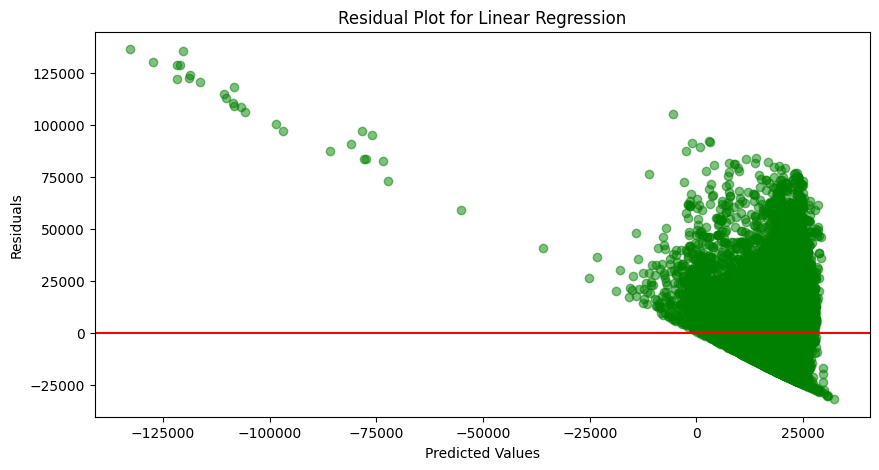

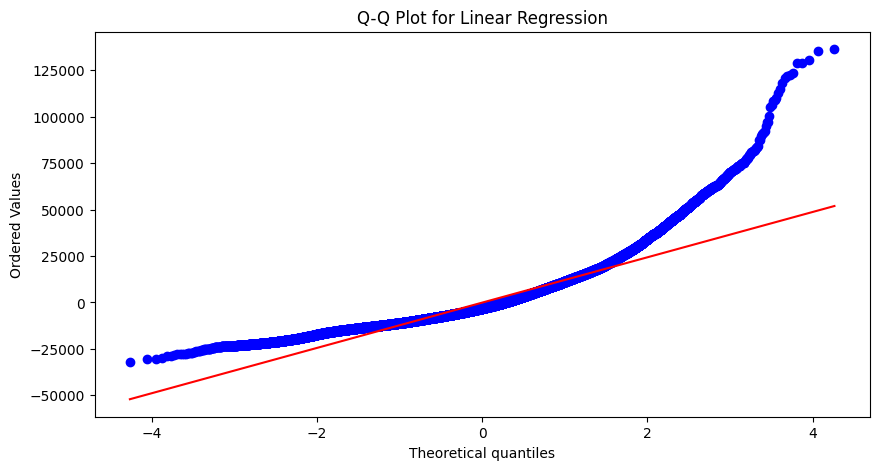

In [46]:
# Predictions and residuals for the baseline Linear Regression model
#y_pred_linear = model_pipeline.predict(X_test)  # Using the model_pipeline which has LinearRegression
#residuals_linear = y_test - y_pred_linear

y_pred = best_model.predict(X_test)
residuals = y_test - y_pred



# Predictions and residuals for the best-performing Ridge model
#y_pred_ridge = best_model.predict(X_test)  # Using the best_model from GridSearchCV

#residuals_ridge = y_test - y_pred_ridge

# Residual Plot for Linear Regression
plt.figure(figsize=(10, 5))
plt.scatter(y_pred, residuals, alpha=0.5, color='green')
plt.title('Residual Plot for Linear Regression')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.axhline(y=0, color='r', linestyle='-')
plt.show()

import scipy.stats as stats

# Q-Q Plot for Linear Regression
plt.figure(figsize=(10, 5))
stats.probplot(residuals, dist="norm", plot=plt)
plt.title('Q-Q Plot for Linear Regression')
plt.show()

### Evaluation

With some modeling accomplished, we aim to reflect on what we identify as a high-quality model and what we are able to learn from this.  We should review our business objective and explore how well we can provide meaningful insight into drivers of used car prices.  Your goal now is to distill your findings and determine whether the earlier phases need revisitation and adjustment or if you have information of value to bring back to your client.


< need to add what was done above and how it leads to the next steps >

In [47]:
results.head()

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_poly__degree,param_regressor,param_regressor__alpha,param_svd__n_components,params,split0_test_R2,...,mean_test_MSE,std_test_MSE,rank_test_MSE,split0_train_MSE,split1_train_MSE,split2_train_MSE,split3_train_MSE,split4_train_MSE,mean_train_MSE,std_train_MSE
0,0.681171,0.136236,0.015807,0.002358,1,Lasso(),0.1,2,"{'poly__degree': 1, 'regressor': Lasso(), 'reg...",0.081965,...,-1.864879e+08,1.730461e+06,28,-1.864899e+08,-1.866550e+08,-1.865652e+08,-1.856757e+08,-1.869967e+08,-1.864765e+08,436294.973875
1,0.660254,0.119229,0.018087,0.004723,1,Lasso(),0.1,10,"{'poly__degree': 1, 'regressor': Lasso(), 'reg...",0.155274,...,-1.713526e+08,1.497262e+06,5,-1.712372e+08,-1.715873e+08,-1.709468e+08,-1.706815e+08,-1.720150e+08,-1.712936e+08,470070.041422
2,0.572298,0.111492,0.015247,0.003969,1,Lasso(),0.1,10,"{'poly__degree': 1, 'regressor': Lasso(), 'reg...",0.155274,...,-1.713526e+08,1.497262e+06,5,-1.712372e+08,-1.715873e+08,-1.709468e+08,-1.706815e+08,-1.720150e+08,-1.712936e+08,470070.041422
3,0.378634,0.054360,0.009249,0.000879,1,Lasso(),1.0,2,"{'poly__degree': 1, 'regressor': Lasso(), 'reg...",0.081964,...,-1.864879e+08,1.730396e+06,29,-1.864899e+08,-1.866550e+08,-1.865652e+08,-1.856757e+08,-1.869967e+08,-1.864765e+08,436294.973536
4,0.413618,0.010262,0.009868,0.000843,1,Lasso(),1.0,10,"{'poly__degree': 1, 'regressor': Lasso(), 'reg...",0.155273,...,-1.713525e+08,1.497161e+06,1,-1.712372e+08,-1.715873e+08,-1.709468e+08,-1.706815e+08,-1.720151e+08,-1.712936e+08,470070.042207


In [48]:
from sklearn.inspection import permutation_importance

# Improving the resulting data obtained by generating a sorted DataFrame with importance
perm_importance = permutation_importance(best_model, X_test, y_test, n_repeats=10, random_state=42, n_jobs=-1)
importances_tr = dict(zip(X_train.columns, perm_importance.importances_mean))
importances_tr = {k : v for k ,v in sorted(importances_tr.items(), key = lambda x: x[1], reverse = True)}
import_df = pd.DataFrame(importances_tr.values(), index=importances_tr.keys(), columns = ['Importances'])
display(import_df)

,Importances
year,0.114365
odometer,0.050834
transmission,0.025174
condition,0.023543
title_status,0.014824
drive,0.013852
manufacturer,0.009828
fuel,0.002195
type,0.001399
model,0.000048


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
 [Text(0, 0, 'year'),
  Text(1, 0, 'odometer'),
  Text(2, 0, 'transmission'),
  Text(3, 0, 'condition'),
  Text(4, 0, 'title_status'),
  Text(5, 0, 'drive'),
  Text(6, 0, 'manufacturer'),
  Text(7, 0, 'fuel'),
  Text(8, 0, 'type'),
  Text(9, 0, 'model'),
  Text(10, 0, 'state')])

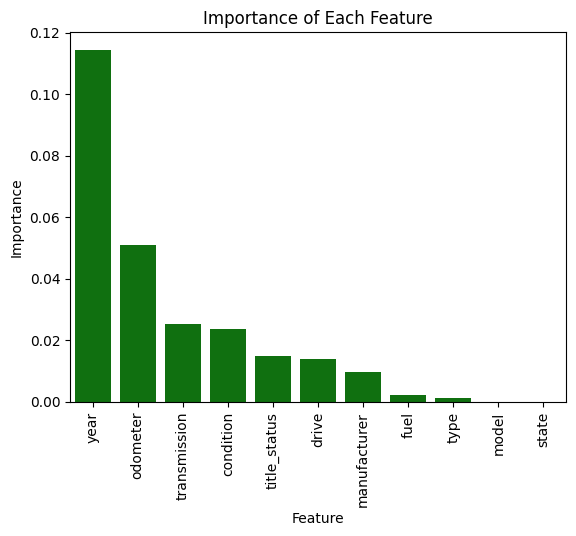

In [49]:
# Visualization of the importance of each feature vs the price
df_importances = import_df.reset_index()

sns.barplot(data = df_importances, x="index", y="Importances", color='green')

plt.xlabel("Feature")
plt.ylabel("Importance")
plt.title('Importance of Each Feature')
plt.xticks(rotation=90)  # Rotate labels by 45 degrees


### Deployment

Now that we've settled on our models and findings, it is time to deliver the information to the client.  You should organize your work as a basic report that details your primary findings.  Keep in mind that your audience is a group of used car dealers interested in fine-tuning their inventory.

In [50]:
#true up the DF name to start with 
 
df_deployment = car_resale_cleaned_sans_outliers.copy()

df_deployment.sample(10)

,price,year,manufacturer,model,condition,fuel,odometer,title_status,transmission,drive,type,state
173389,8995,2016.0,11.0,11484.0,3.0,3.0,11000.0,4.0,0.0,0.0,9.0,17.0
128627,11995,2009.0,19.0,15691.0,0.0,3.0,70540.0,0.0,1.0,0.0,9.0,11.0
278080,3500,2004.0,40.0,9217.0,2.0,3.0,192230.0,2.0,0.0,0.0,9.0,34.0
39657,27000,1999.0,34.0,5926.0,2.0,3.0,122000.0,0.0,1.0,0.0,9.0,4.0
415647,3500,2009.0,14.0,12741.0,2.0,3.0,218000.0,0.0,0.0,1.0,0.0,48.0
178070,6500,2010.0,14.0,15561.0,0.0,4.0,58500.0,0.0,0.0,1.0,9.0,21.0
116164,50427,2020.0,14.0,14200.0,2.0,3.0,15168.0,0.0,0.0,0.0,9.0,9.0
426234,19468,2018.0,21.0,10368.0,2.0,5.0,52735.0,0.0,0.0,0.0,7.0,48.0
381362,6900,2012.0,11.0,17488.0,3.0,3.0,150000.0,0.0,0.0,0.0,9.0,43.0
191595,1200,2005.0,17.0,19671.0,1.0,3.0,205000.0,0.0,0.0,1.0,5.0,19.0


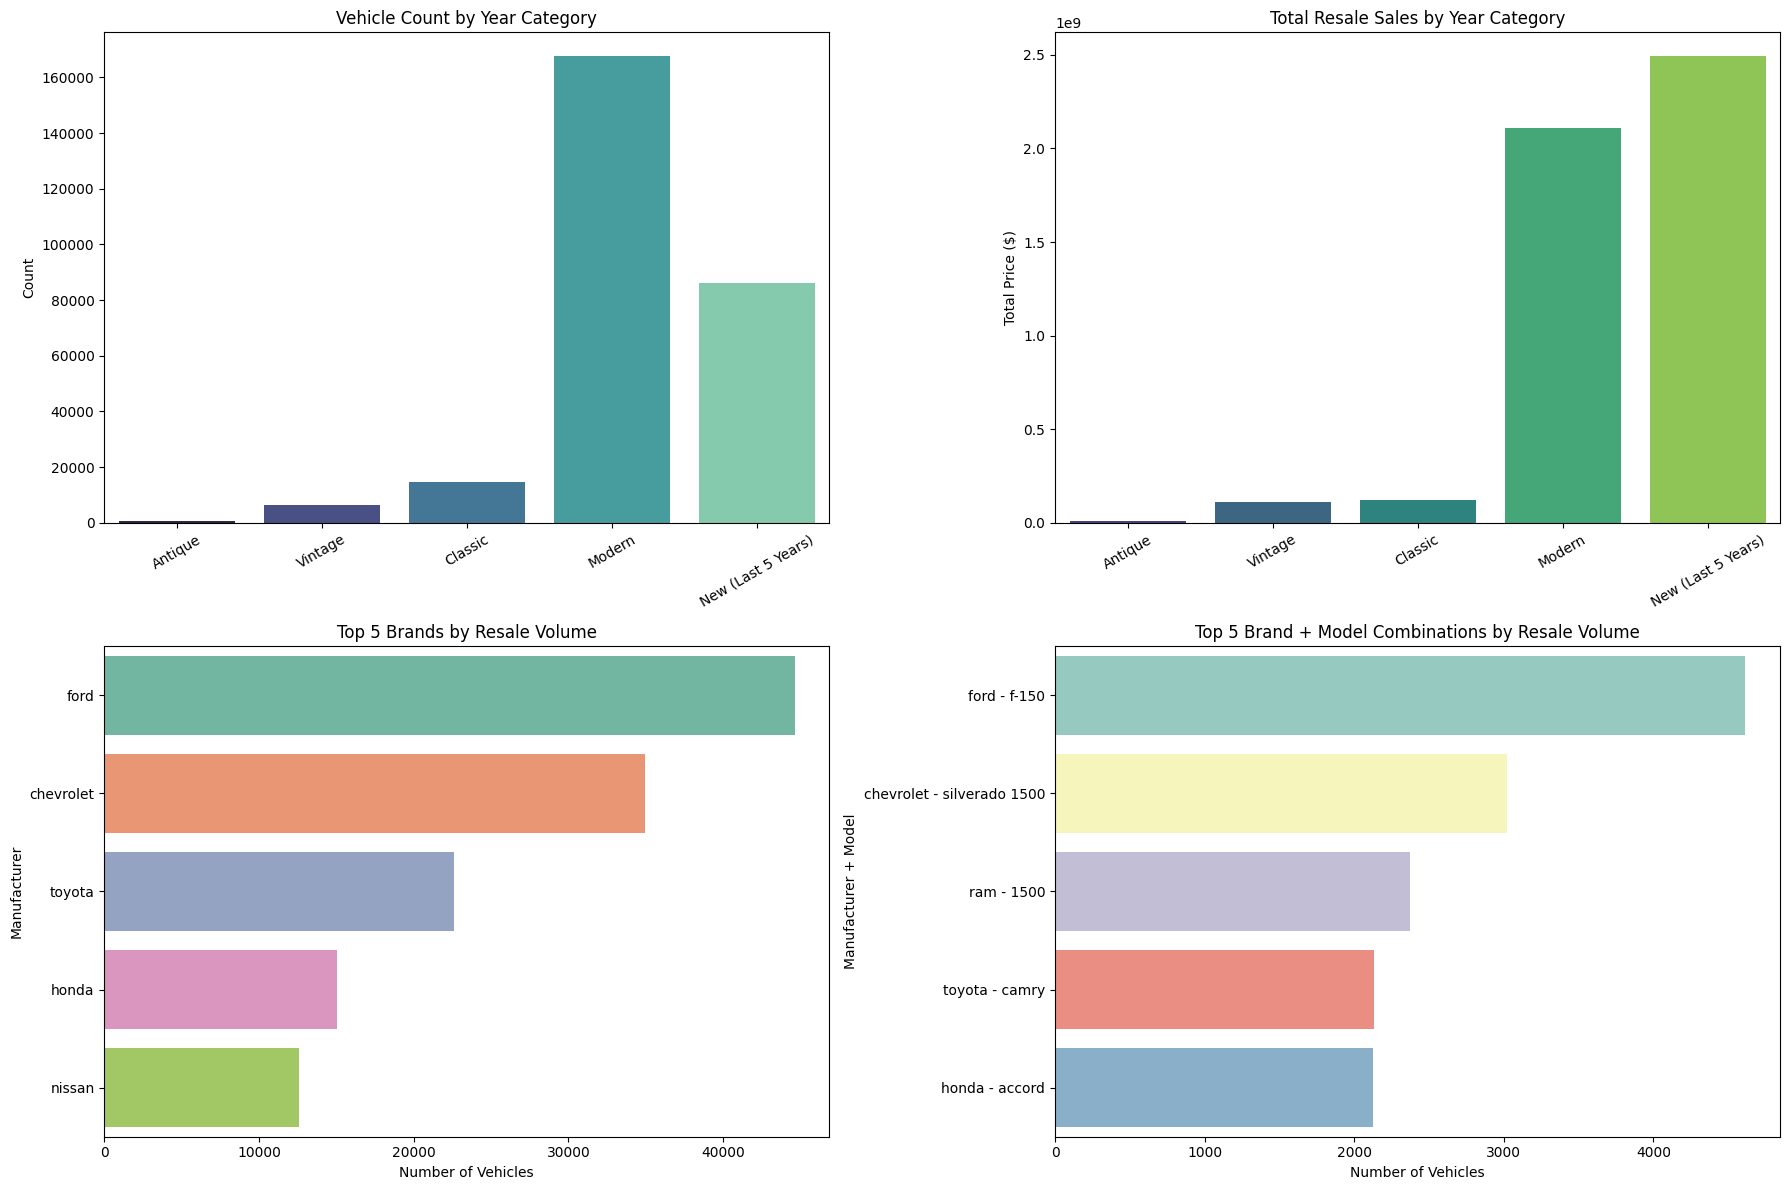

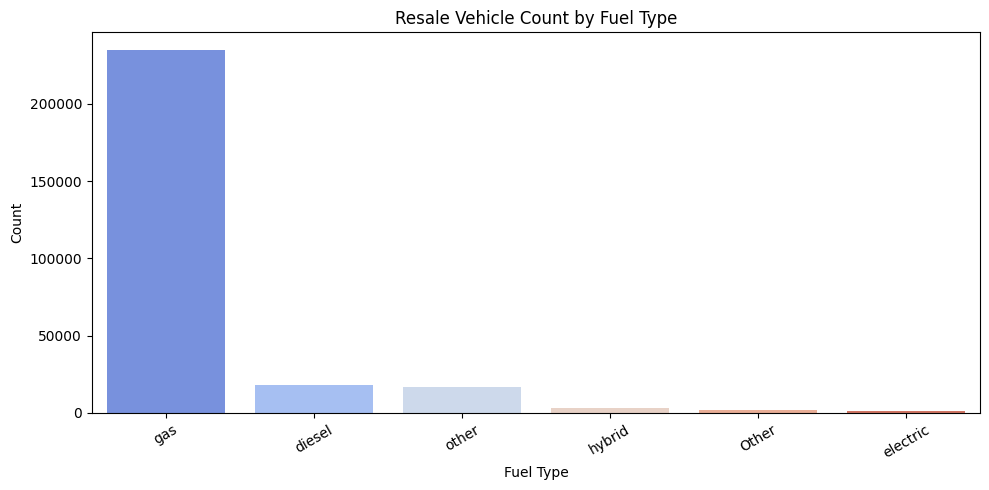

<Figure size 1600x700 with 0 Axes>

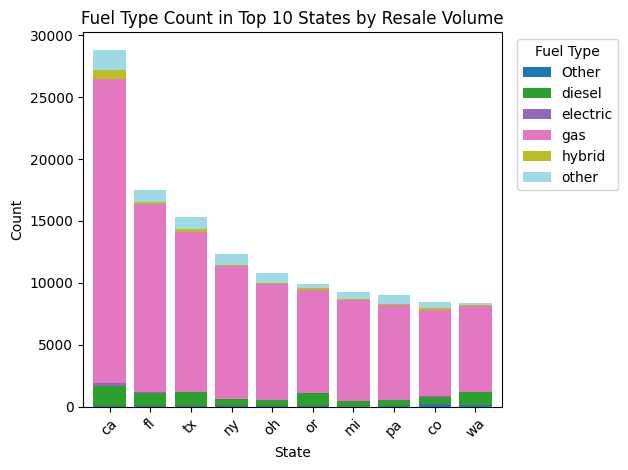

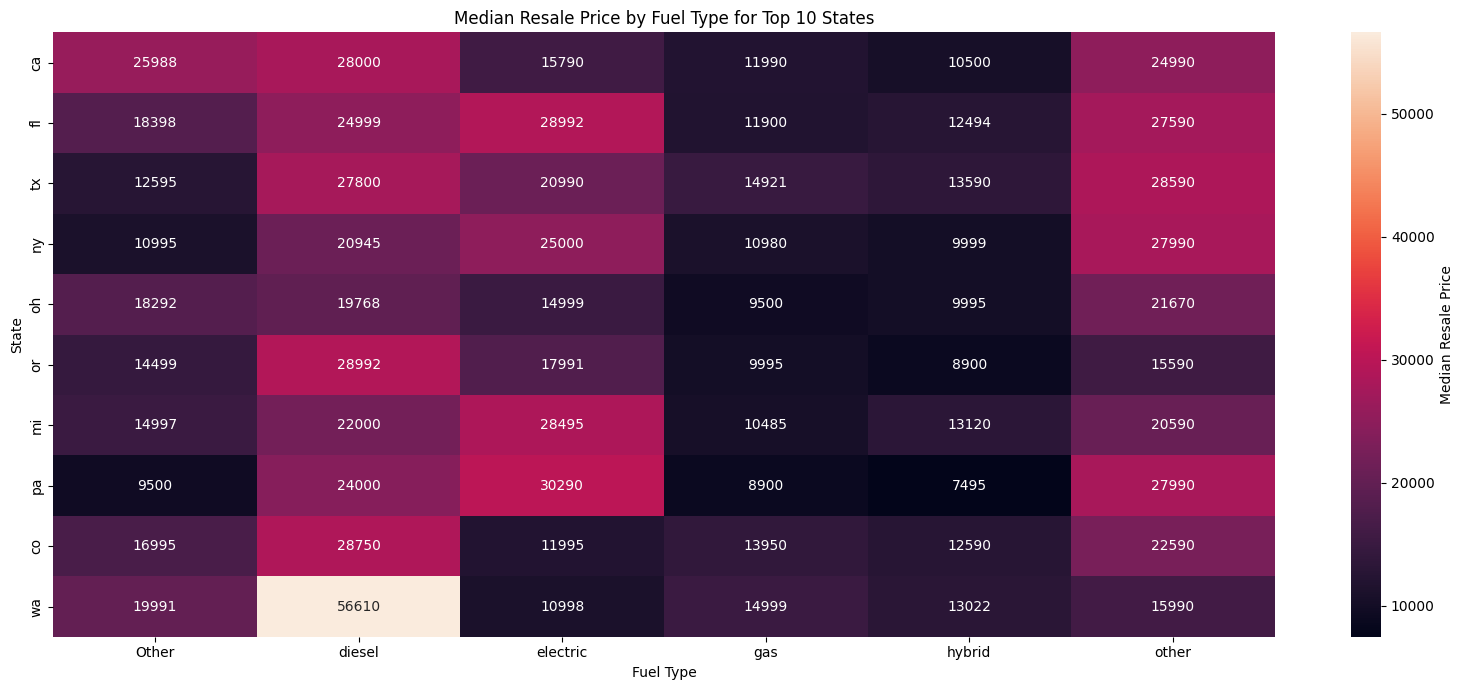

In [51]:
df_plot = car_resale_cleaned[
    (car_resale_cleaned['price'] > 100) &
    (car_resale_cleaned['price'] < 100000)
].copy()

year_bins = [0, 1948, 1979, 1999, 2015, df_plot['year'].max() + 1]
year_labels = ['Antique', 'Vintage', 'Classic', 'Modern', 'New (Last 5 Years)']

df_plot['year_category'] = pd.cut(
    df_plot['year'],
    bins=year_bins,
    labels=year_labels,
    right=True,
    include_lowest=True
)

sales_by_category = df_plot.groupby('year_category')['price'].sum().reindex(year_labels)
count_by_category = df_plot['year_category'].value_counts().reindex(year_labels)

top_brands = df_plot['manufacturer'].value_counts().head(5)
top_brand_models = (
    df_plot.groupby(['manufacturer', 'model'])
    .size()
    .sort_values(ascending=False)
    .head(5)
)

fuel_counts = df_plot['fuel'].value_counts()

top_states = df_plot['state'].value_counts().head(10).index.tolist()
state_fuel_counts = (
    df_plot[df_plot['state'].isin(top_states)]
    .groupby(['state', 'fuel'])
    .size()
    .unstack(fill_value=0)
    .reindex(top_states)
)

state_fuel_median_price = (
    df_plot[df_plot['state'].isin(top_states)]
    .groupby(['state', 'fuel'])['price']
    .median()
    .unstack()
    .reindex(top_states)
)

fig, axes = plt.subplots(2, 2, figsize=(18, 12))

sns.barplot(
    x=count_by_category.index,
    y=count_by_category.values,
    ax=axes[0, 0],
    palette='mako'
)
axes[0, 0].set_title('Vehicle Count by Year Category')
axes[0, 0].set_xlabel('')
axes[0, 0].set_ylabel('Count')
axes[0, 0].tick_params(axis='x', rotation=30)

sns.barplot(
    x=sales_by_category.index,
    y=sales_by_category.values,
    ax=axes[0, 1],
    palette='viridis'
)
axes[0, 1].set_title('Total Resale Sales by Year Category')
axes[0, 1].set_xlabel('')
axes[0, 1].set_ylabel('Total Price ($)')
axes[0, 1].tick_params(axis='x', rotation=30)

sns.barplot(
    x=top_brands.values,
    y=top_brands.index,
    ax=axes[1, 0],
    palette='Set2'
)
axes[1, 0].set_title('Top 5 Brands by Resale Volume')
axes[1, 0].set_xlabel('Number of Vehicles')
axes[1, 0].set_ylabel('Manufacturer')

sns.barplot(
    x=top_brand_models.values,
    y=[f'{make} - {model}' for make, model in top_brand_models.index],
    ax=axes[1, 1],
    palette='Set3'
)
axes[1, 1].set_title('Top 5 Brand + Model Combinations by Resale Volume')
axes[1, 1].set_xlabel('Number of Vehicles')
axes[1, 1].set_ylabel('Manufacturer + Model')

plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.barplot(
    x=fuel_counts.index,
    y=fuel_counts.values,
    palette='coolwarm'
)
plt.title('Resale Vehicle Count by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Count')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

plt.figure(figsize=(16, 7))
state_fuel_counts.plot(
    kind='bar',
    stacked=True,
    colormap='tab20',
    width=0.8
)
plt.title('Fuel Type Count in Top 10 States by Resale Volume')
plt.xlabel('State')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.legend(title='Fuel Type', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

plt.figure(figsize=(16, 7))
sns.heatmap(
    state_fuel_median_price.fillna(0),
    annot=True,
    fmt='.0f',
    cmap='rocket',
    cbar_kws={'label': 'Median Resale Price'}
)
plt.title('Median Resale Price by Fuel Type for Top 10 States')
plt.xlabel('Fuel Type')
plt.ylabel('State')
plt.tight_layout()
plt.show()

In [53]:
# Identify the year with the highest number of sales
year_counts = df_plot['year'].value_counts()
top_year = year_counts.idxmax()
top_year_count = year_counts.max()
top_year_category = df_plot.loc[df_plot['year'] == top_year, 'year_category'].iloc[0]

print(f"Year with most sales: {top_year}")
print(f"Sales volume in that year: {top_year_count}")
print(f"Year category: {top_year_category}")

# Get the top 5 models sold in that year with median price and volume
top_models_year = (
    df_plot[df_plot['year'] == top_year]
    .groupby(['manufacturer', 'model'])
    .agg(
        volume=('price', 'size'),
        median_price=('price', 'median'),
        median_odometer=('odometer', 'median')
    )
    .reset_index()
    .sort_values(by='volume', ascending=False)
    .head(5)
)

display(top_models_year)

Year with most sales: 2018.0
Sales volume in that year: 22454
Year category: New (Last 5 Years)


,manufacturer,model,volume,median_price,median_odometer
1252,ford,f-150,505,37788.0,43697.0
1201,ford,escape,226,18365.5,36254.0
898,chevrolet,silverado 1500,203,35305.0,44913.0
2044,jeep,grand cherokee,197,30995.0,34102.0
845,chevrolet,equinox,167,19991.0,39466.0


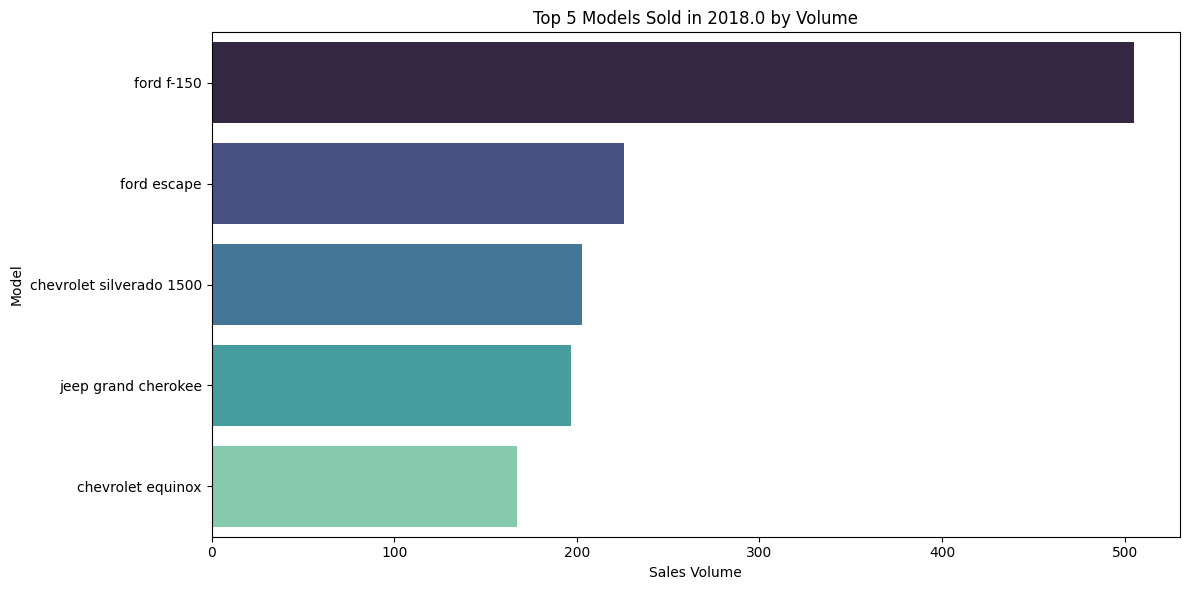

In [54]:
top_models_year['model_label'] = top_models_year['manufacturer'] + ' ' + top_models_year['model']

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_models_year,
    x='volume',
    y='model_label',
    palette='mako'
)
plt.title(f'Top 5 Models Sold in {top_year} by Volume')
plt.xlabel('Sales Volume')
plt.ylabel('Model')
plt.tight_layout()
plt.show()

In [52]:
current_year_category = 'New (Last 5 Years)'

df_current_year = df_plot[df_plot['year_category'] == current_year_category]

top_five_models = (
    df_current_year
    .groupby(['manufacturer', 'model', 'fuel'])
    .agg(
        count=('price', 'size'),
        median_price=('price', lambda x: x.median() if not x.empty else np.nan),
        median_odometer=('odometer', lambda x: x.median() if not x.empty else np.nan)
    )
    .reset_index()
    .sort_values(by='count', ascending=False)
    .head(5)
)

top_five_models

,manufacturer,model,fuel,count,median_price,median_odometer
3971,ford,f-150,gas,1404,35988.0,48522.0
2685,chevrolet,silverado 1500,gas,815,35969.0,45904.0
8919,ram,1500,gas,767,32998.0,47235.0
3770,ford,escape,gas,588,17553.5,42830.0
3888,ford,explorer,gas,547,27598.0,55531.0


### Key finding 

#### During EDA it was found that many features had missing data - this was addressed using imputation 
#### THe price feature also had outliers and this was addressed by restricting the values between range of 100 to 100000$
#### to enable that most features were used, I did Ordinal encoding for categorical features as it was efficient and thsi was followed by scalling the data before applying different models
#### For modeling we used GridSearchCV along with a param grid and for polynomial and SVD along with L1 and L2 regularization. The run concluded that the best model is 
    Best Parameters: {'poly__degree': 1, 'regressor': Lasso(), 'regressor__alpha': 1.0, 'svd__n_components': 10}
    Best R2 Score from CV: 0.154989922668683
    Pipeline(steps=[('scaler', StandardScaler()), 
                    ('poly', PolynomialFeatures(degree=1)), 
                    ('svd', TruncatedSVD(n_components=10)), 
                    ('regressor', Lasso())]) 
#### Subseqeuntly we analyzed the resutls across various dimensions for car reseller. 
#### The next steps 
- Get updated data set with current data to validate the model and check if it needs a refresh / tuning
- evaluate other alogritms (either direclty or a hybrid approach) and explore if a good balance betwwen training time with better Test acurracy is feasible v/s the currently used classifiers 
